# Exercício 1

Todo número real $x \in [0,1]$ pode ser representado, ou aproximado, por meio de uma **decomposição binária**. Nessa representação, utilizamos apenas os dígitos 0 e 1.

Considerando os primeiros $D$ dígitos binários, podemos escrever

$$
x = \frac{b_1}{2} + \frac{b_2}{2^2} + \frac{b_3}{2^3} + \cdots + \frac{b_D}{2^D},
$$

em que cada $b_i \in \{0,1\}$.

Por exemplo, o número binário $0.101_2$ corresponde, na base decimal, a

$$
0.101_2
=
1\cdot\frac{1}{2}
+
0\cdot\frac{1}{2^2}
+
1\cdot\frac{1}{2^3}
=
0.625.
$$

Assim, ao gerar aleatoriamente uma sequência de zeros e uns, podemos utilizá-la como os dígitos de uma expansão binária e, dessa forma, construir números aleatórios no intervalo $[0,1]$.


Utilizando a função `np.random.choice`, gere uma sequência de tamanho $D$ composta por dígitos 0 ou 1.

1. Utilizando essa sequência e um laço `for`, construa um número aleatório entre 0 e 1 a partir de sua decomposição binária, conforme descrito acima.

2. Utilizando a função `np.arange`, repita o procedimento do item anterior **sem utilizar um laço `for`**. Faça o cálculo por meio de operações vetorizadas, utilizando a multiplicação termo a termo entre os dígitos binários e as respectivas potências de $1/2$.

3. Utilizando o procedimento vetorizado desenvolvido no item 2, gere uma amostra de tamanho $N$ de números aleatórios no intervalo $[0,1]$. Em seguida, gere outra amostra de mesmo tamanho utilizando a função `np.random.uniform`. Compare as distribuições das duas amostras por meio de histogramas e discuta se o procedimento baseado na decomposição binária produz resultados compatíveis com uma distribuição uniforme.

4. Repita o passo 3 várias vezes com diferentes valores de $D$ e comente qual o efeito de aumentar ou diminuir $D$.

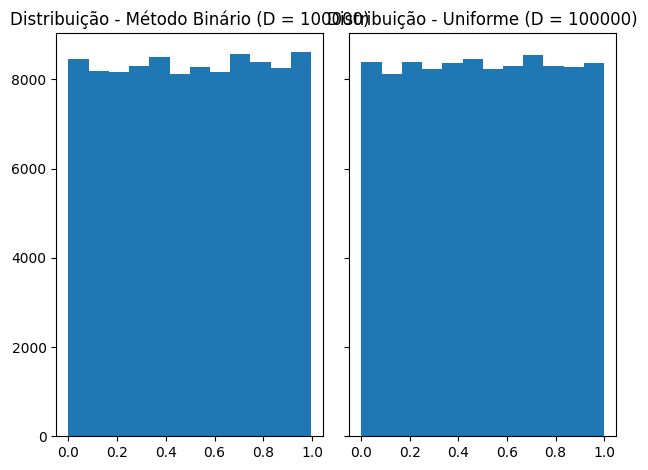

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

tamanho_binario = 8 # Tamanho do número binário usado para gerar os valores entre 0 e 1

tamanho_amostra = 100000
qtde_barras = 12 # Quantidade de barras do histograma

# Item 1
def binarioAleatorio(d):
  result = 0
  valores = np.random.choice([0,1], size=d)

  print(valores)
  for i in range(len(valores)):
    result += valores[i] * 1/(2**(i+1))
  return result

# Item 2
def binarioAleatorioNoFor(d):
  valores = np.random.choice([0,1], size=d)
  expoentes = np.arange(d, step = 1) + 1
  potencias = 1/(2**expoentes)

  return np.sum(valores * potencias)
# Item 3 e 4
def amostraBinarioAleatorio(d):
  amostra = []
  for i in range(d):
    amostra.append(binarioAleatorioNoFor(tamanho_binario))

  return amostra

amostra_metodo_binario = amostraBinarioAleatorio(tamanho_amostra)
amostra_np_uniform = np.random.uniform(0,1, size = tamanho_amostra)


fig, axs = plt.subplots(1, 2, sharey=True, tight_layout=True) # https://matplotlib.org/stable/gallery/statistics/hist.html

axs[0].hist(amostra_metodo_binario, bins=qtde_barras)
axs[0].set(title="Distribuição - Método Binário (D = {})".format(tamanho_amostra))
axs[1].hist(amostra_np_uniform, bins=qtde_barras)
axs[1].set(title="Distribuição - Uniforme (D = {})".format(tamanho_amostra))

plt.show()

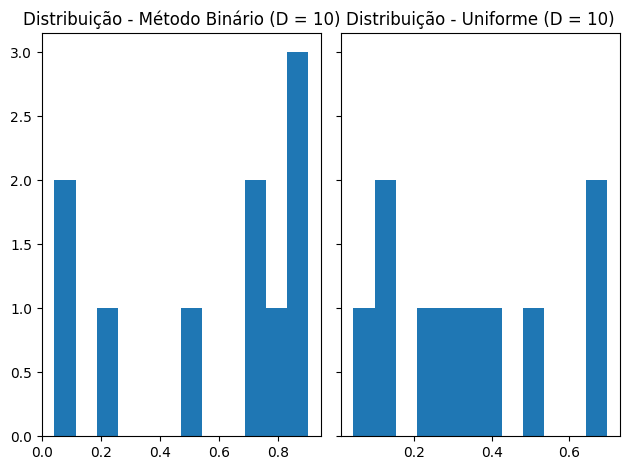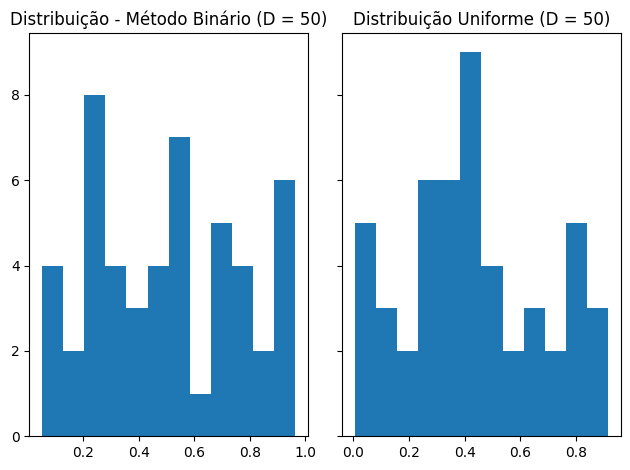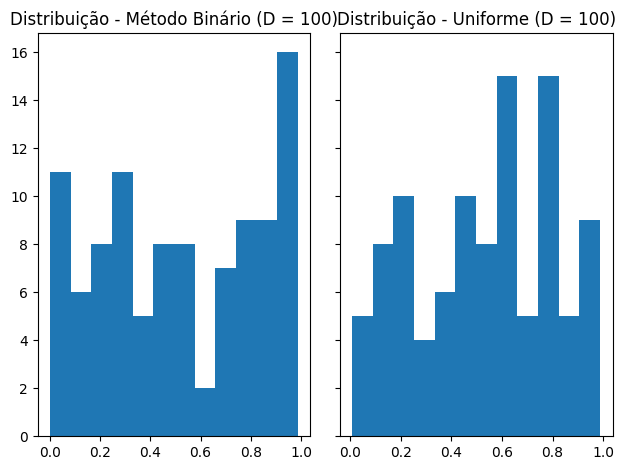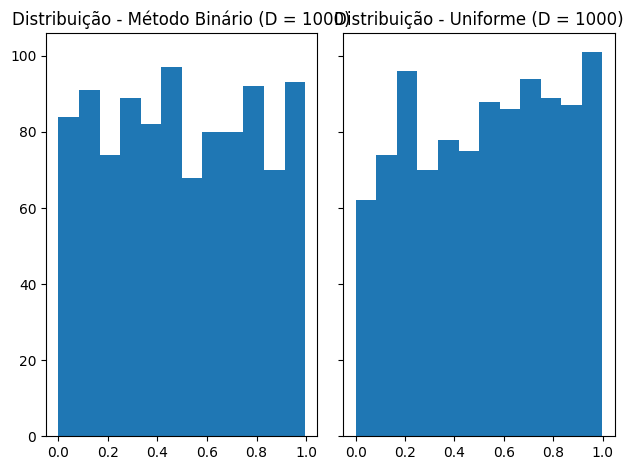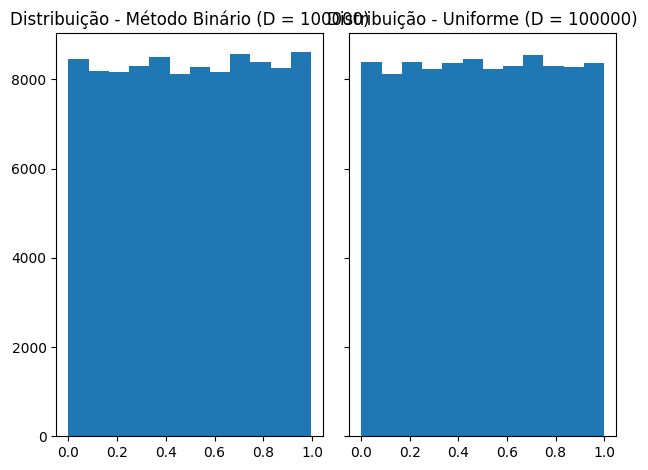

**Como ilustrado nas imagens acima, o experimento não produz valores compatíveis com a distribuição uniforme para valores pequenos, mas assintoticamente se aproxima dela.**

# Exercício 2 — Simulação de variáveis aleatórias a partir da distribuição uniforme

Apesar de o exercício anterior mostrar como podemos gerar variáveis uniformes em $[0,1]$ a partir de lançamentos de moedas, a partir de agora, e ao longo do curso, assumiremos que o único mecanismo de geração de números aleatórios disponível é a geração de variáveis uniformes no intervalo $[0,1]$.

Neste exercício, vamos utilizar variáveis uniformes para simular algumas das variáveis aleatórias discretas vistas em sala.

A ideia fundamental será transformar uma variável

$$
U \sim \text{Uniforme}(0,1)
$$

em outra variável aleatória por meio de uma função apropriada.

Em todos os itens, considere uma amostra de tamanho $N$.

## 1. Gerando a amostra uniforme

Utilizando `np.random.uniform`, gere uma amostra

$$
U_1,\ldots,U_N
$$

de variáveis aleatórias independentes com distribuição uniforme em $[0,1]$.

Essa será a única fonte de aleatoriedade utilizada nos itens seguintes.

In [ ]:
import numpy as np

def amostraUniforme(N):
  return np.random.uniform(0,1, size = N)

print(amostraUniforme(6))

[0.27618596 0.31180117 0.24146289 0.38311864 0.27067668 0.66267346]


## 2. Variável Bernoulli

Considere uma variável aleatória Bernoulli com parâmetro $p$, isto é,

$$
P(X=1)=p
\qquad \text{e} \qquad
P(X=0)=1-p.
$$

Utilizando a amostra uniforme gerada no item anterior:

1. Gere uma amostra Bernoulli utilizando um `for` e uma estrutura `if/else`.

2. Crie uma função `f` que transforme valores uniformes em valores `0` ou `1` de acordo com o parâmetro $p$. Em seguida, aplique diretamente essa função à amostra uniforme, isto é, `f(amostra)`.

3. Calcule a média e a variância da amostra Bernoulli obtida e compare-as com os valores teóricos

$$
\mathbb{E}[X]=p
\qquad \text{e} \qquad
\operatorname{Var}(X)=p(1-p).
$$

In [ ]:
import numpy as np

N_amostra = 10000

def amostraUniforme(N):
  return np.random.uniform(0,1, size = N)
def amostraBernoulli(amostra, p):
  amostra_b = []
  for ponto in amostra:
    if ponto < (1 - p):
      amostra_b.append(0)
    else:
      amostra_b.append(1)
  return amostra_b

amostra_u = amostraUniforme(N_amostra)
amostra_bernoulli = amostraBernoulli(amostra_u, 0.7)

#print(amostra_u)
#print(amostra_bernoulli)
print("Média Bernoulli: {} \nVariância Bernoulli: {}".format(np.mean(amostra_bernoulli), np.var(amostra_bernoulli, ddof=1))) # ddof é utilizado no denominador do calculo da variância -> (N - ddof) | No caso N - 1 seria variância amostral



Média Bernoulli: 0.6966 
Variância Bernoulli: 0.21134843999999994


## 3. Lançamento de um dado justo

Considere um dado justo de seis faces, de modo que

$$
P(X=k)=\frac{1}{6}, \qquad k=1,\ldots,6.
$$

Utilizando a amostra uniforme gerada no item 1:

1. Gere uma amostra de lançamentos do dado utilizando um `for` e uma estrutura `if/elif/else`.

2. Crie uma função `f` que transforme valores uniformes em valores de `1` a `6`. Em seguida, aplique diretamente a função à amostra uniforme, isto é, `f(amostra)`.

3. Você consegue encontrar uma forma mais simples de fazer essa transformação, sem utilizar `if/elif/else`? Pense no que acontece ao multiplicar um valor uniforme por 6 e considerar apenas sua parte inteira.

4. Calcule a frequência relativa de cada face e compare-a com o valor teórico $1/6$.

5. Calcule a média e a variância da amostra e compare-as com os valores teóricos: $\mathbb{E}[X], \operatorname{Var}(X).$ Você pode calcular usando a fórmula $\operatorname{Var}(X) = \mathbb{E}[X^2] - \mathbb{E}[X]^2$.

6. Repita o procedimento anterior para um dado viciado com probabilidades

$$
P(X=1)=0.05,\quad
P(X=2)=0.10,\quad
P(X=3)=0.15,
$$

$$
P(X=4)=0.20,\quad
P(X=5)=0.20,\quad
P(X=6)=0.30.
$$

Construa uma função `f` que transforme a amostra uniforme em lançamentos desse dado. Compare as frequências relativas obtidas com as probabilidades teóricas acima e compare também a média e a variância amostrais com os valores teóricos.


In [ ]:

import numpy as np

esperanca_teorica = 3.5 # dado de 6 faces não viciado
variancia_teorica = 2.92 # dado de 6 faces não viciado

esperanca_teorica_dado_viciado = 4.3
variancia_teorica_dado_viciado = 2.31

valores_teoricos_dado_justo = [1/6, 1/6, 1/6, 1/6, 1/6, 1/6]
valores_teoricos_dado_viciado = [0.05, 0.1, 0.15, 0.2, 0.2, 0.3]

def amostraUniforme(N):
  return np.random.uniform(0,1, size = N)

def amostraDado(amostra): # Dado de 6 faces não viciado, ou seja, p constante entre as faces
  amostra_dado = []
  for ponto in amostra:
    if ponto < 1/6:
      amostra_dado.append(1)
    elif ponto < 2/6:
      amostra_dado.append(2)
    elif ponto < 3/6:
      amostra_dado.append(3)
    elif ponto < 4/6:
      amostra_dado.append(4)
    elif ponto < 5/6:
      amostra_dado.append(5)
    else:
      amostra_dado.append(6)
  return amostra_dado

def amostraDadoNp(amostra): # numpy trickery
  intervalos = np.arange(0,1,step=1/6)

  return (np.digitize(amostra, intervalos))

def amostraDadoNoIf(amostra):
  return np.ceil(amostra * 6).astype(int)

def calculaFreq(amostra_dado, valores_teoricos): # Recebe a amostra contendo valores de 1 a 6 representando as faces
  tamanho_amostra = len(amostra_dado)

  # Solução não dinâmica e bem feia, mas funciona
  qtde_f1 = np.count_nonzero(amostra_dado == 1)
  qtde_f2 = np.count_nonzero(amostra_dado == 2)
  qtde_f3 = np.count_nonzero(amostra_dado == 3)
  qtde_f4 = np.count_nonzero(amostra_dado == 4)
  qtde_f5 = np.count_nonzero(amostra_dado == 5)
  qtde_f6 = np.count_nonzero(amostra_dado == 6)

  classe_resposta = {
      "1": {
          "Frequencia Absoluta": qtde_f1,
          "Frequencia Relativa": (qtde_f1 / tamanho_amostra),
          "Diferença do Valor Teórico": "{:+.4f}".format((qtde_f1 / tamanho_amostra) - valores_teoricos[0])
      },
      "2": {
          "Frequencia Absoluta": qtde_f2,
          "Frequencia Relativa": (qtde_f2 / tamanho_amostra),
          "Diferença do Valor Teórico": "{:+.4f}".format((qtde_f2 / tamanho_amostra) - valores_teoricos[1])
      },
      "3": {
          "Frequencia Absoluta": qtde_f3,
          "Frequencia Relativa": (qtde_f3 / tamanho_amostra),
          "Diferença do Valor Teórico": "{:+.4f}".format((qtde_f3 / tamanho_amostra) - valores_teoricos[2])
      },
      "4": {
          "Frequencia Absoluta": qtde_f4,
          "Frequencia Relativa": (qtde_f4 / tamanho_amostra),
          "Diferença do Valor Teórico": "{:+.4f}".format((qtde_f4 / tamanho_amostra) - valores_teoricos[3])
      },
      "5": {
          "Frequencia Absoluta": qtde_f5,
          "Frequencia Relativa": (qtde_f5 / tamanho_amostra),
          "Diferença do Valor Teórico": "{:+.4f}".format((qtde_f5 / tamanho_amostra) - valores_teoricos[4])
      },
      "6": {
          "Frequencia Absoluta": qtde_f6,
          "Frequencia Relativa": (qtde_f6 / tamanho_amostra),
          "Diferença do Valor Teórico": "{:+.4f}".format((qtde_f6 / tamanho_amostra) - valores_teoricos[5])
      }
  }
  return classe_resposta

def amostraDadoViciado(amostra):
  # intervalos é um array contendo o acúmulo de probabilidades para cada face
  intervalos = np.array([0, 0.05, 0.15, 0.3, 0.5, 0.7]) #uso do np.array é pra poder usar o digitize

  return (np.digitize(amostra, intervalos))

# 1 e 2 - Conversão da uniforme para a amostra do dado
#print(amostraDado(amostra_u))

# 3 - Conversão da uniforme para a amostra do dado sem usar for/if/else
#print(amostraDadoNoIf(amostra_u))

# 4 - Calculo das frequências relativas
amostra_u = amostraUniforme(30)
amostra_d = amostraDadoNoIf(amostra_u)
print(amostra_u)
#print(amostra_d)

#print(calculaFreq(amostra_d, valores_teoricos_dado_justo))

# 5 - Comparação de estatísticas teóricas com as da amostra
media_amostra = np.mean(amostra_d)
variancia_amostra = np.var(amostra_d, ddof=1)

#print("Média Amostra: {} | Média Teórica: {}\nVariância Amostra: {} | Variância Teórica: {}".format(media_amostra, esperanca_teorica, variancia_amostra, variancia_teorica))

# 6 - Dado viciado
amostra_dado_viciado = amostraDadoViciado(amostra_u)
media_amostra_dado_viciado = np.mean(amostra_dado_viciado)
variancia_amostra_dado_viciado = np.var(amostra_dado_viciado, ddof=1)
print(amostra_dado_viciado)

print(calculaFreq(amostra_dado_viciado, valores_teoricos_dado_viciado))
print("Média Amostra: {} | Média Teórica: {}\nVariância Amostra: {} | Variância Teórica: {}".format(media_amostra_dado_viciado, esperanca_teorica_dado_viciado, variancia_amostra_dado_viciado, variancia_teorica_dado_viciado))



[0.52480655 0.73404643 0.74707772 0.87447571 0.15950921 0.70567963
 0.82875374 0.8153604  0.74358974 0.88274188 0.52796276 0.41832441
 0.44461662 0.92294506 0.26966428 0.85054627 0.79038091 0.40173053
 0.8273845  0.73000202 0.12895669 0.89139621 0.42345301 0.10753886
 0.91090203 0.59531752 0.18907631 0.58417231 0.51135209 0.66266128]
[5 6 6 6 3 6 6 6 6 6 5 4 4 6 3 6 6 4 6 6 2 6 4 2 6 5 3 5 5 5]
{'1': {'Frequencia Absoluta': 0, 'Frequencia Relativa': 0.0, 'Diferença do Valor Teórico': '-0.0500'}, '2': {'Frequencia Absoluta': 2, 'Frequencia Relativa': 0.06666666666666667, 'Diferença do Valor Teórico': '-0.0333'}, '3': {'Frequencia Absoluta': 3, 'Frequencia Relativa': 0.1, 'Diferença do Valor Teórico': '-0.0500'}, '4': {'Frequencia Absoluta': 4, 'Frequencia Relativa': 0.13333333333333333, 'Diferença do Valor Teórico': '-0.0667'}, '5': {'Frequencia Absoluta': 6, 'Frequencia Relativa': 0.2, 'Diferença do Valor Teórico': '+0.0000'}, '6': {'Frequencia Absoluta': 15, 'Frequencia Relativa': 0.5

## 4. Distribuição Binomial

Podemos interpretar uma variável aleatória binomial pensando em lançamentos de uma moeda. Suponha que lançamos uma moeda $n$ vezes, de forma independente, e que a probabilidade de obter **cara** em cada lançamento seja $p$.

Se contarmos o número total de caras obtidas nesses $n$ lançamentos, esse número segue uma distribuição binomial:

$$
X \sim \mathrm{Binomial}(n,p).
$$

Assim, uma variável binomial nada mais é do que a soma de $n$ variáveis Bernoulli independentes:

$$
X = X_1 + \cdots + X_n,
\qquad
X_i \sim \mathrm{Bernoulli}(p),
$$

onde $X_i=1$ representa uma cara e $X_i=0$ representa uma coroa.

1. Utilizando o procedimento desenvolvido anteriormente para gerar variáveis Bernoulli, gere uma amostra de tamanho $N$ de variáveis com distribuição $\mathrm{Binomial}(n,p)$.

2. Calcule a média e a variância da amostra e compare-as com os valores teóricos

$$
\mathbb{E}[X]=np
\qquad \text{e} \qquad
\operatorname{Var}(X)=np(1-p).
$$

3. Gere uma segunda amostra de tamanho $N$ utilizando `np.random.binomial` com os mesmos parâmetros $n$ e $p$. Compare as duas amostras por meio de histogramas.


Média Binomial Amostra: 4.9958 | Média Teórica: 5.0
Variância Binomial Amostra: 2.54858236 | Variância Teórica: 2.5


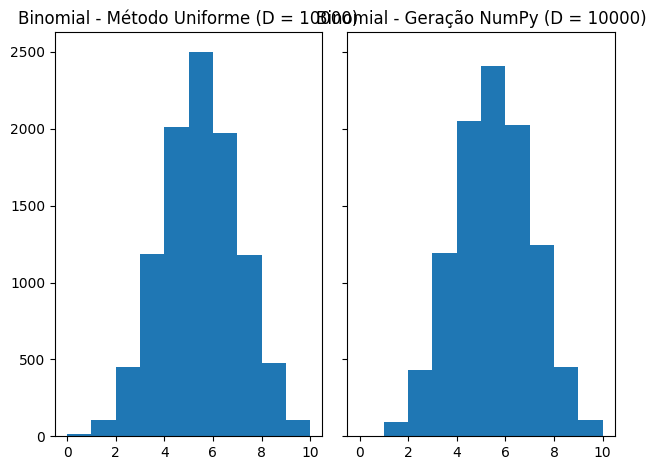

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

n_amostra = 10
p_amostra = 0.5
N = 10000

qtde_barras = n_amostra

esperanca_teorica = n_amostra * p_amostra
variancia_teorica = n_amostra * p_amostra * (1 - p_amostra)

def amostraBernoulli(n, p): # seria mais limpo fazer tudo em uma função, mas separei para deixar claro que usei o mesmo método da bernoulli do exercício passado
  amostra_u = np.random.uniform(0,1, size = n)
  amostra_b = []
  for ponto in amostra_u:
    if ponto < (1 - p):
      amostra_b.append(0)
    else:
      amostra_b.append(1)
  return amostra_b

def amostraBinomial(n, p, N): # n = lançamentos da moeda | p = probabilidade de sucesso (cara) | N = quantidade de amostras
  amostra_binomial = []
  for i in range(N):
    amostra_binomial.append(sum(amostraBernoulli(n, p)))
  return amostra_binomial

amostra_binomial = amostraBinomial(n_amostra, p_amostra, N)

media_binomial_amostra = np.mean(amostra_binomial)
variancia_binomial_amostra = np.var(amostra_binomial, ddof=1)

amostra_binomial_np = np.random.binomial(n_amostra, p_amostra, size=N)

#print(amostra_binomial)
print("Média Binomial Amostra: {} | Média Teórica: {}\nVariância Binomial Amostra: {} | Variância Teórica: {}".format(media_binomial_amostra, esperanca_teorica, variancia_binomial_amostra, variancia_teorica))

fig, axs = plt.subplots(1, 2, sharey=True, tight_layout=True) # https://matplotlib.org/stable/gallery/statistics/hist.html

axs[0].hist(amostra_binomial, bins=qtde_barras)
axs[0].set(title="Binomial - Método Uniforme (D = {})".format(N))
axs[1].hist(amostra_binomial_np, bins=qtde_barras)
axs[1].set(title="Binomial - Geração NumPy (D = {})".format(N))

plt.show()

## 5. Distribuição Multinomial

A distribuição multinomial é uma generalização da distribuição binomial.

Na distribuição binomial, realizamos $n$ lançamentos de uma moeda e contamos quantas vezes ocorreu um dos dois resultados possíveis. Na distribuição multinomial, fazemos a mesma ideia, mas com $k$ resultados possíveis.

Por exemplo, considere um dado de $k$ lados, em que a face $i$ aparece com probabilidade $p_i$, com

$$
p_1+\cdots+p_k=1.
$$

Após $n$ lançamentos, definimos

$$
X=(X_1,\ldots,X_k),
$$

onde $X_i$ representa o número de vezes que a face $i$ apareceu. Nesse caso,

$$
X \sim \mathrm{Multinomial}(n,p_1,\ldots,p_k),
$$

e

$$
X_1+\cdots+X_k=n.
$$

Considere agora um dado de **4 lados** com probabilidades

$$
P(X=1)=0.10,\qquad
P(X=2)=0.20,\qquad
P(X=3)=0.30,\qquad
P(X=4)=0.40.
$$

1. Utilizando o procedimento desenvolvido anteriormente, realize $n$ lançamentos desse dado e conte quantas vezes cada uma das quatro faces apareceu.

2. Repita esse experimento $N$ vezes, gerando uma amostra de tamanho $N$ de vetores com distribuição multinomial.

3. Para cada face $i$, calcule a média amostral de $X_i$ e compare-a com o valor teórico

$$
\mathbb{E}[X_i]=np_i.
$$

4. Gere uma segunda amostra utilizando `np.random.multinomial` com os mesmos parâmetros e compare os resultados obtidos pelos dois métodos.

5. Verifique que, em cada realização, a soma das contagens das $k$ faces é igual a $n$.

6. Para cada face $i$, calcule a variância amostral de $X_i$ e compare-a com

$$
\operatorname{Var}(X_i)=np_i(1-p_i).
$$

7. Escolha duas faces distintas e calcule a covariância amostral entre suas contagens. Compare-a com

$$
\operatorname{Cov}(X_i,X_j)=-np_ip_j.
$$

Interprete o sinal negativo dessa covariância.

In [ ]:
import numpy as np

valores_p_dado = np.array([0.1, 0.2, 0.3, 0.4]) # esse array precisa receber de maneira ordenada as probabilidades de cada face
dimensao_dado = len(valores_p_dado) # quantas faces o dado tem

n_amostra_multinomial = 5
N_amostra_multinomial = 10000

media_faces_teorica = valores_p_dado*n_amostra_multinomial
variancia_faces_teorica = valores_p_dado*n_amostra_multinomial*(1-valores_p_dado)

def amostraMultinomial(n, valores_p, N):
  AMOSTRAS_M = [] # array contendo multiplas (N) amostras
  intervalos = np.array([0, 0.1, 0.3, 0.6])

  for i in range(N):
    amostra_m = [] # amostra (multinomial)
    amostra_u = np.random.uniform(0,1, size = n)

    qtde_faces = len(valores_p) # a quantidade de probabilidades é a quantidade de faces do dado | nesse exemplo = 4

    faces = np.digitize(amostra_u, intervalos) # pegando o valor da uniforme e verificando (entre os intervalos) qual face representa

    for face in range(qtde_faces):
      amostra_m.append(np.count_nonzero(faces == (face + 1))) # conta quantas vezes cada face se repete na amostra | face + 1 por que não temos face = 0
    AMOSTRAS_M.append(amostra_m)

  return AMOSTRAS_M

def mediaFacesMultinomial(amostra):
  media_faces_amostra = np.mean(amostra, axis=0) # axis = 0 aplica o método por coluna | 1 -> por linha

  return media_faces_amostra

def varianciaFacesMultinomial(amostra):
  return np.var(amostra, axis=0, ddof=1) # muito bom esse numpy viu

def verificaContagemFaces(amostra, n): # retorna true se a soma de todas as contagens é igual a n
  soma_contagem = np.sum(amostra, axis=1) # axis = 1 soma os arrays por linha
  #print(soma_contagem)
  return not(np.isin(True, soma_contagem != n))


amostra_multinomial_np = np.random.multinomial(n_amostra_multinomial, valores_p_dado, size = N_amostra_multinomial)
amostra_multinomial = np.array(amostraMultinomial(n_amostra_multinomial, valores_p_dado, N_amostra_multinomial))
#print(amostra_multinomial)
#print(amostra_multinomial_np)

#print(verificaContagemFaces(amostra_multinomial, n_amostra_multinomial))
#print(verificaContagemFaces(amostra_multinomial_np, n_amostra_multinomial))

medias_amostra_multinomial = mediaFacesMultinomial(amostra_multinomial)
medias_amostra_multinomial_np = mediaFacesMultinomial(amostra_multinomial_np)
print("Médias Amostra Multinomial: {} | Médias Teóricas Multinomial: {}".format(medias_amostra_multinomial, media_faces_teorica))
print("Numpy -> Médias Amostra Multinomial: {} | Médias Teóricas Multinomial: {}".format(medias_amostra_multinomial_np, media_faces_teorica))

print("############################################################################")

variancia_amostra_multinomial = varianciaFacesMultinomial(amostra_multinomial)
variancia_amostra_multinomial_np = varianciaFacesMultinomial(amostra_multinomial_np)
print("Variâncias Amostra Multinomial: {} | Variâncias Teóricas Multinomial: {}".format(variancia_amostra_multinomial, variancia_faces_teorica))
print("Numpy -> Variâncias Amostra Multinomial: {} | Variâncias Teóricas Multinomial: {}".format(variancia_amostra_multinomial_np, variancia_faces_teorica))

# Covariâncias
cov_teorica = -n_amostra_multinomial * 0.2 * 0.4
face_2 = amostra_multinomial[:, 1] # esse slicing aqui só é possível com um array do numpy | forma um novo array contendo os valores que estão no índice 1 de cada array
face_4 = amostra_multinomial[:, 3]

cov_amostral = np.cov(face_2, face_4, ddof=1)
print("Covariância Amostral (Faces 2 e 4): {}".format(cov_amostral[0,1]))
print("Covariância Teórica  (Faces 2 e 4): {}".format(cov_teorica))


Médias Amostra Multinomial: [0.4988 1.0016 1.5193 1.9803] | Médias Teóricas Multinomial: [0.5 1.  1.5 2. ]
Numpy -> Médias Amostra Multinomial: [0.5012 0.9968 1.4895 2.0125] | Médias Teóricas Multinomial: [0.5 1.  1.5 2. ]
############################################################################
Variâncias Amostra Multinomial: [0.4514437  0.80727817 1.06313382 1.18203011] | Variâncias Teóricas Multinomial: [0.45 0.8  1.05 1.2 ]
Numpy -> Variâncias Amostra Multinomial: [0.4564442  0.80667043 1.06939669 1.2134651 ] | Variâncias Teóricas Multinomial: [0.45 0.8  1.05 1.2 ]
Covariância Amostral (Faces 2 e 4): -0.3889073707370726
Covariância Teórica  (Faces 2 e 4): -0.4
